In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!ls "/content/drive/MyDrive/logistics_project"

'Parcels and Boxes.v1i.yolov8.zip'


In [ ]:
!nvidia-smi

Wed Nov 11 07:04:55 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
#install Ultralytics  YOLO library
!pip install -q ultralytics


In [ ]:
!mkdir -p /content/Parcels_and_Boxes
!unzip -q "/content/drive/MyDrive/logistics_project/Parcels and Boxes.v1i.yolov8.zip" -d /content/Parcels_and_Boxes
!ls /content/Parcels_and_Boxes

replace /content/Parcels_and_Boxes/data.yaml? [y]es, [n]o, [A]ll, [N]one, [r]ename: A
data.yaml  README.dataset.txt  README.roboflow.txt  test  train  valid


In [ ]:
%%writefile prep_dataset.py
import os, shutil, glob, collections, sys

SRC = sys.argv[1]
DST = sys.argv[2]
NAMES = ["Box", "Parcel"]

def to_bbox(vals):
    if len(vals) == 4:
        x, y, w, h = vals
    else:
        xs, ys = vals[0::2], vals[1::2]
        x1, x2, y1, y2 = min(xs), max(xs), min(ys), max(ys)
        x, y, w, h = (x1 + x2) / 2, (y1 + y2) / 2, x2 - x1, y2 - y1
    clip = lambda v: max(0.0, min(1.0, v))
    return clip(x), clip(y), clip(w), clip(h)

stats = collections.Counter()
for split in ["train", "valid", "test"]:
    os.makedirs(f"{DST}/{split}/images", exist_ok=True)
    os.makedirs(f"{DST}/{split}/labels", exist_ok=True)
    for lf in glob.glob(f"{SRC}/{split}/labels/*.txt"):
        out = []
        for line in open(lf).read().strip().splitlines():
            p = line.split()
            if len(p) < 5: continue
            c = int(p[0]); x, y, w, h = to_bbox(list(map(float, p[1:])))
            if w < 0.005 or h < 0.005:
                stats["dropped_tiny"] += 1; continue
            out.append(f"{c} {x:.6f} {y:.6f} {w:.6f} {h:.6f}")
            stats[f"{split}_{NAMES[c]}"] += 1
        name = os.path.basename(lf)
        open(f"{DST}/{split}/labels/{name}", "w").write("\n".join(out))
        img = name[:-4] + ".jpg"
        shutil.copy(f"{SRC}/{split}/images/{img}", f"{DST}/{split}/images/{img}")
        stats[f"{split}_images"] += 1

abs_dst = os.path.abspath(DST)
open(f"{DST}/data.yaml", "w").write(
    f"path: {abs_dst}\ntrain: train/images\nval: valid/images\ntest: test/images\n"
    f"nc: {len(NAMES)}\nnames: {NAMES}\n")
for k in sorted(stats): print(k, stats[k])

Writing prep_dataset.py


In [ ]:
!python prep_dataset.py /content/Parcels_and_Boxes /content/dataset

dropped_tiny 2
test_Box 996
test_Parcel 736
test_images 604
train_Box 6645
train_Parcel 4907
train_images 4194
valid_Box 1797
valid_Parcel 1357
valid_images 1190


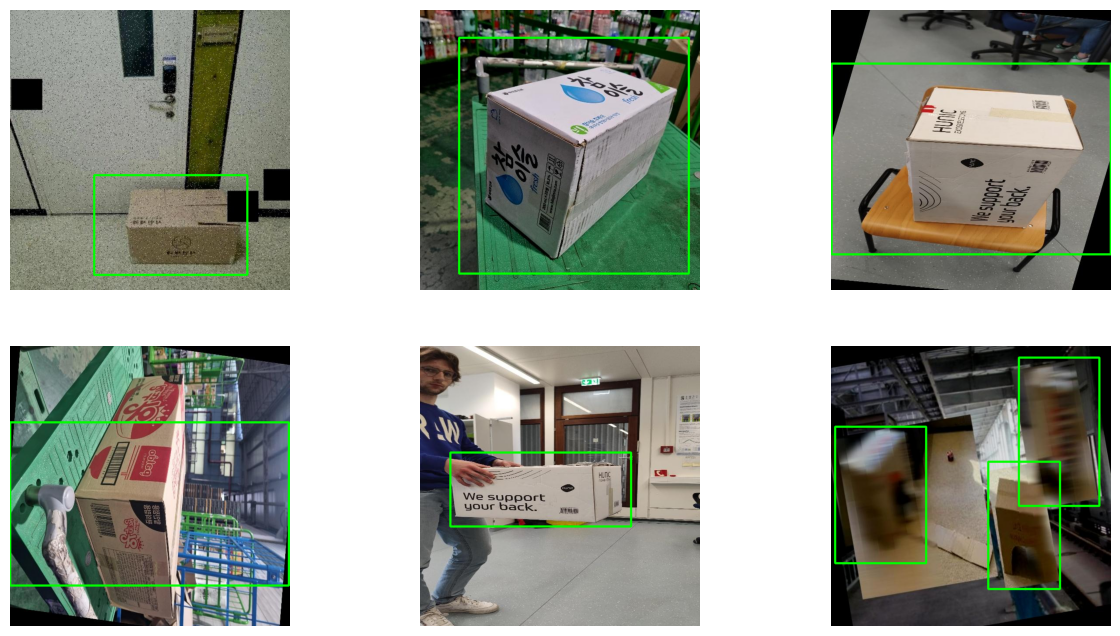

In [ ]:
import glob, random, cv2
import matplotlib.pyplot as plt

files = random.sample(glob.glob('/content/dataset/train/images/*.jpg'), 6)
plt.figure(figsize=(15, 8))
for i, f in enumerate(files):
    img = cv2.cvtColor(cv2.imread(f), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    lab = f.replace('images', 'labels').replace('.jpg', '.txt')
    for line in open(lab).read().split('\n'):
        if not line.strip(): continue
        c, x, y, bw, bh = map(float, line.split())
        x1, y1 = int((x-bw/2)*w), int((y-bh/2)*h)
        x2, y2 = int((x+bw/2)*w), int((y+bh/2)*h)
        color = (0, 255, 0) if int(c) == 0 else (255, 0, 0)  # green=Box, red=Parcel
        cv2.rectangle(img, (x1, y1), (x2, y2), color, 4)
    plt.subplot(2, 3, i+1); plt.imshow(img); plt.axis('off')
plt.show()

# choosing te model and test the pipeline


In [ ]:
#a quick smoke test
from ultralytics import YOLO

model = YOLO('yolov8s.pt')   # downloads pretrained weights automatically

model.train(
    data='/content/dataset/data.yaml',
    epochs=1,
    imgsz=640,
    batch=16,
    fraction=0.1,        # use only 10% of the data, for this test
    project='/content/runs',
    name='smoke',
    workers=2
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=0.1, freez

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7851c612ca50>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04804

In [ ]:
# training
from ultralytics import YOLO

model = YOLO('yolov8s.pt')

model.train(
    data='/content/dataset/data.yaml',
    epochs=40,
    imgsz=640,
    batch=16,
    patience=10,          # stop early if no improvement for 10 epochs
    project='/content/drive/MyDrive/logistics_project/runs',
    name='parcel_box_v8s',
    workers=2
)

Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=parcel_box_v8s, nbs=64, nms=None, opset=None, optimize=False, 

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7851c61c5940>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04804

#evaluate test set

In [ ]:
from ultralytics import YOLO

model = YOLO('/content/drive/MyDrive/logistics_project/runs/parcel_box_v8s/weights/best.pt')

metrics = model.val(
    data='/content/dataset/data.yaml',
    split='test',
    imgsz=640,
    project='/content/drive/MyDrive/logistics_project/runs',
    name='test_eval'
)

print("mAP50:   ", round(metrics.box.map50, 3))
print("mAP50-95:", round(metrics.box.map, 3))
print("Precision:", round(metrics.box.mp, 3))
print("Recall:   ", round(metrics.box.mr, 3))

Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,126,358 parameters, 0 gradients, 28.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 14.4±13.2 MB/s, size: 30.5 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/dataset/test/labels... 68 images, 2 backgrounds, 0 corrupt: 11% ━─────────── 68/604 147.1it/s 0.3s<3.6s

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (108576768 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


val: Scanning /content/dataset/test/labels... 604 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 604/604 426.4it/s 1.4s
val: /content/dataset/test/images/box_aug_1680_jpg.rf.d4bf1f4064ed18eeae6bee1d57c96bf8.jpg: 1 duplicate labels removed
val: /content/dataset/test/images/box_aug_3146_jpg.rf.d7dfe91bdc90c9004ab65775ed3b2ddf.jpg: 1 duplicate labels removed
val: /content/dataset/test/images/im_806_jpg.rf.a0b0ade367deb545072d0c6a3a4179ba.jpg: 1 duplicate labels removed
val: /content/dataset/test/images/imgv19_2242_jpg.rf.d91cd64c6545107a37cf4a3820d92ace.jpg: 1 duplicate labels removed
val: New cache created: /content/dataset/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 38/38 2.8it/s 13.7s
                   all        604       1728      0.929      0.899      0.955      0.871
                   Box        565        994      0.949      0.922      0.977      0.913
                Parcel         90        

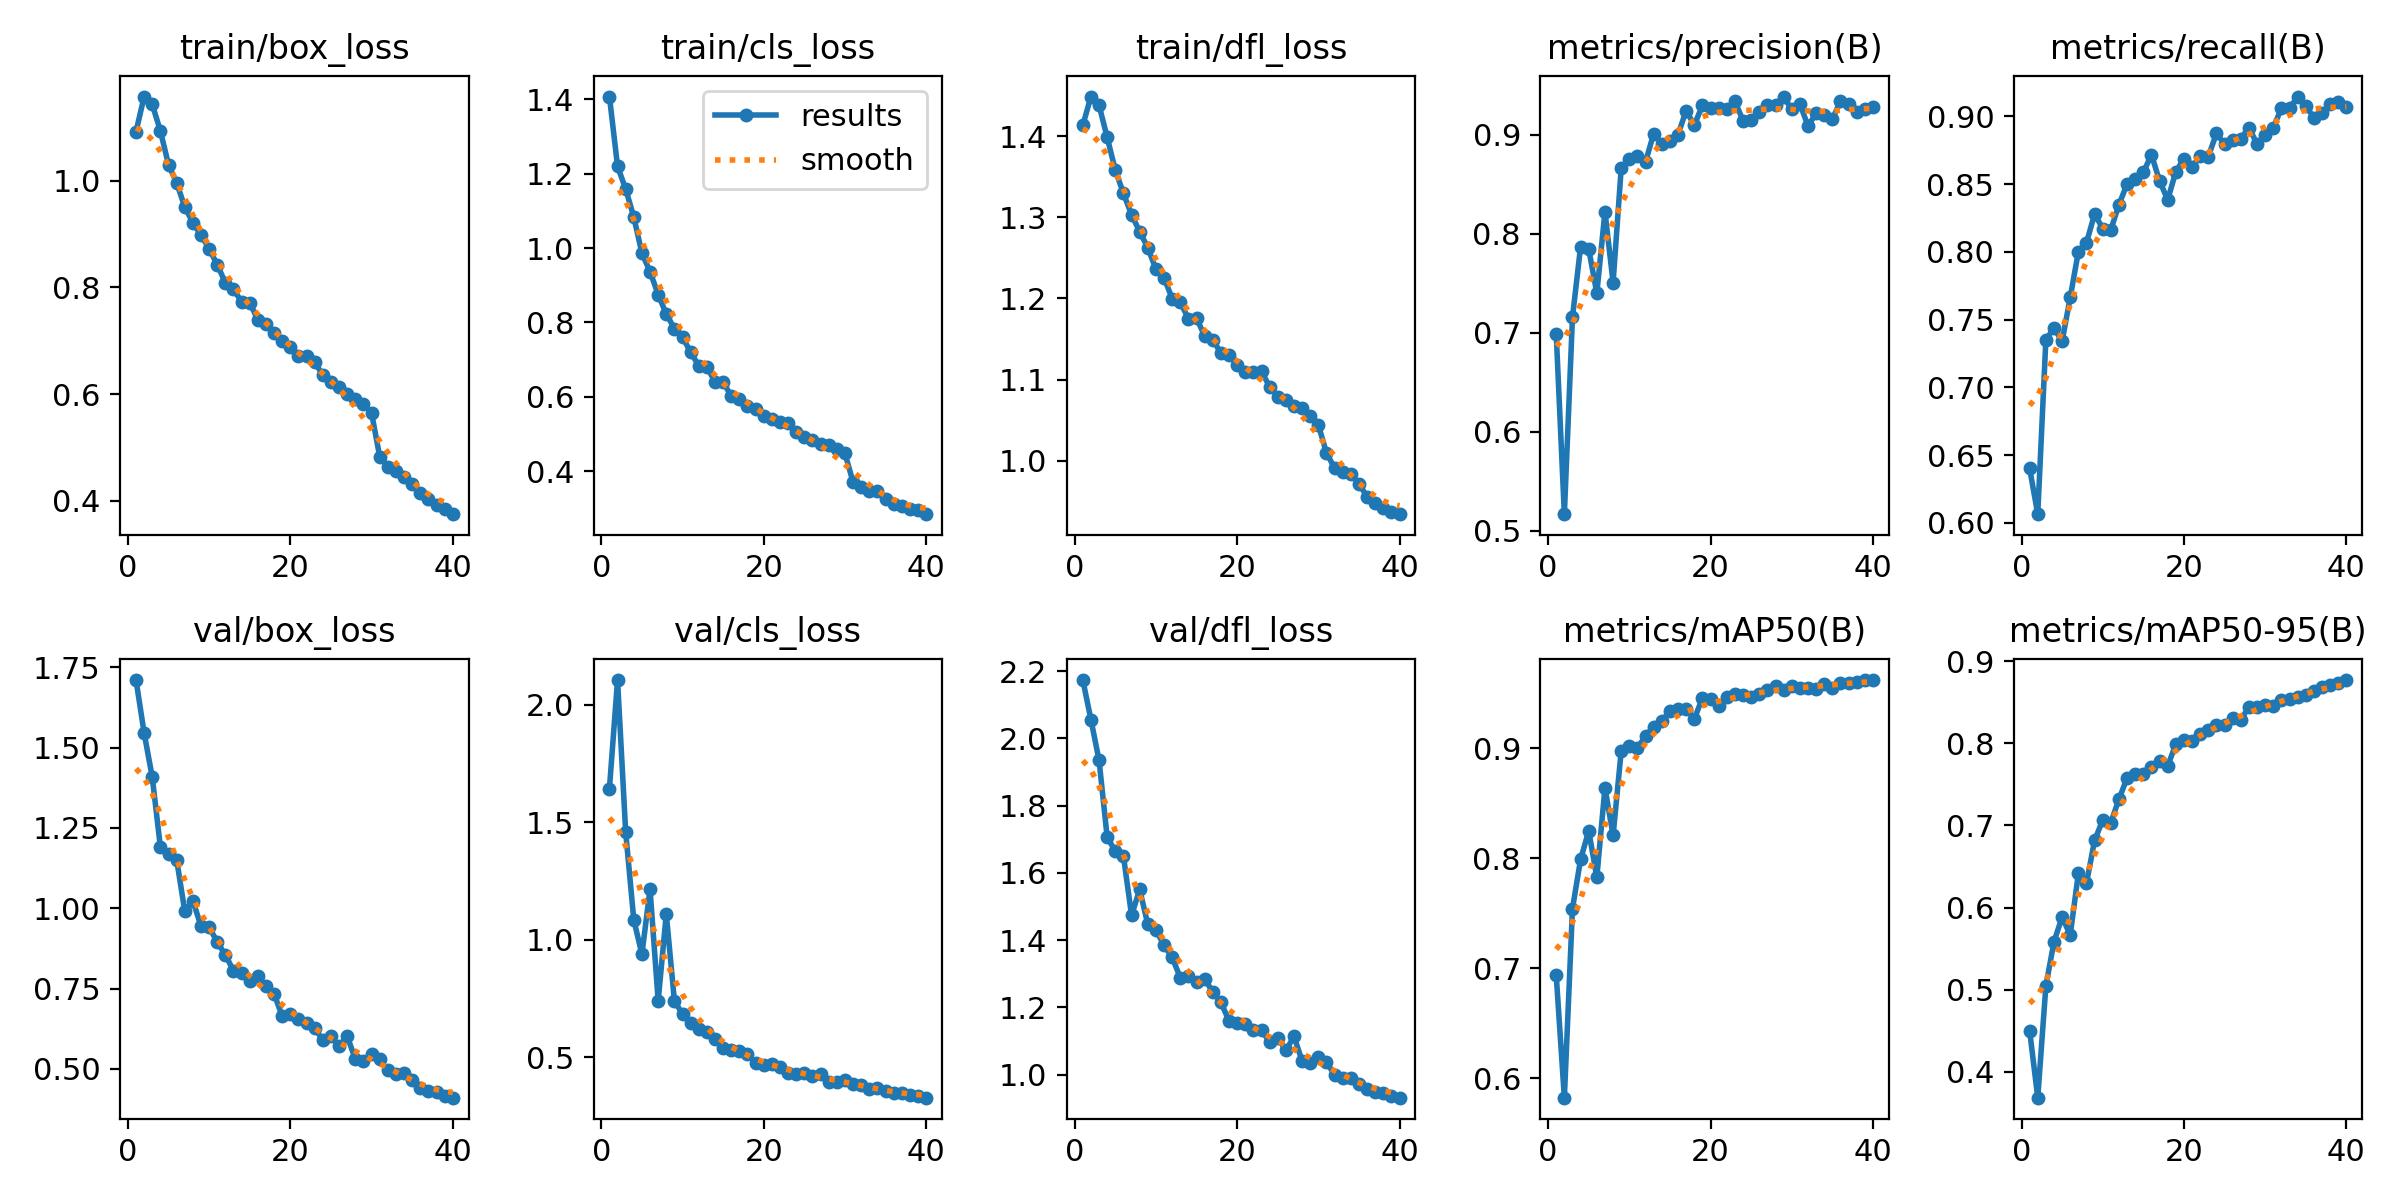

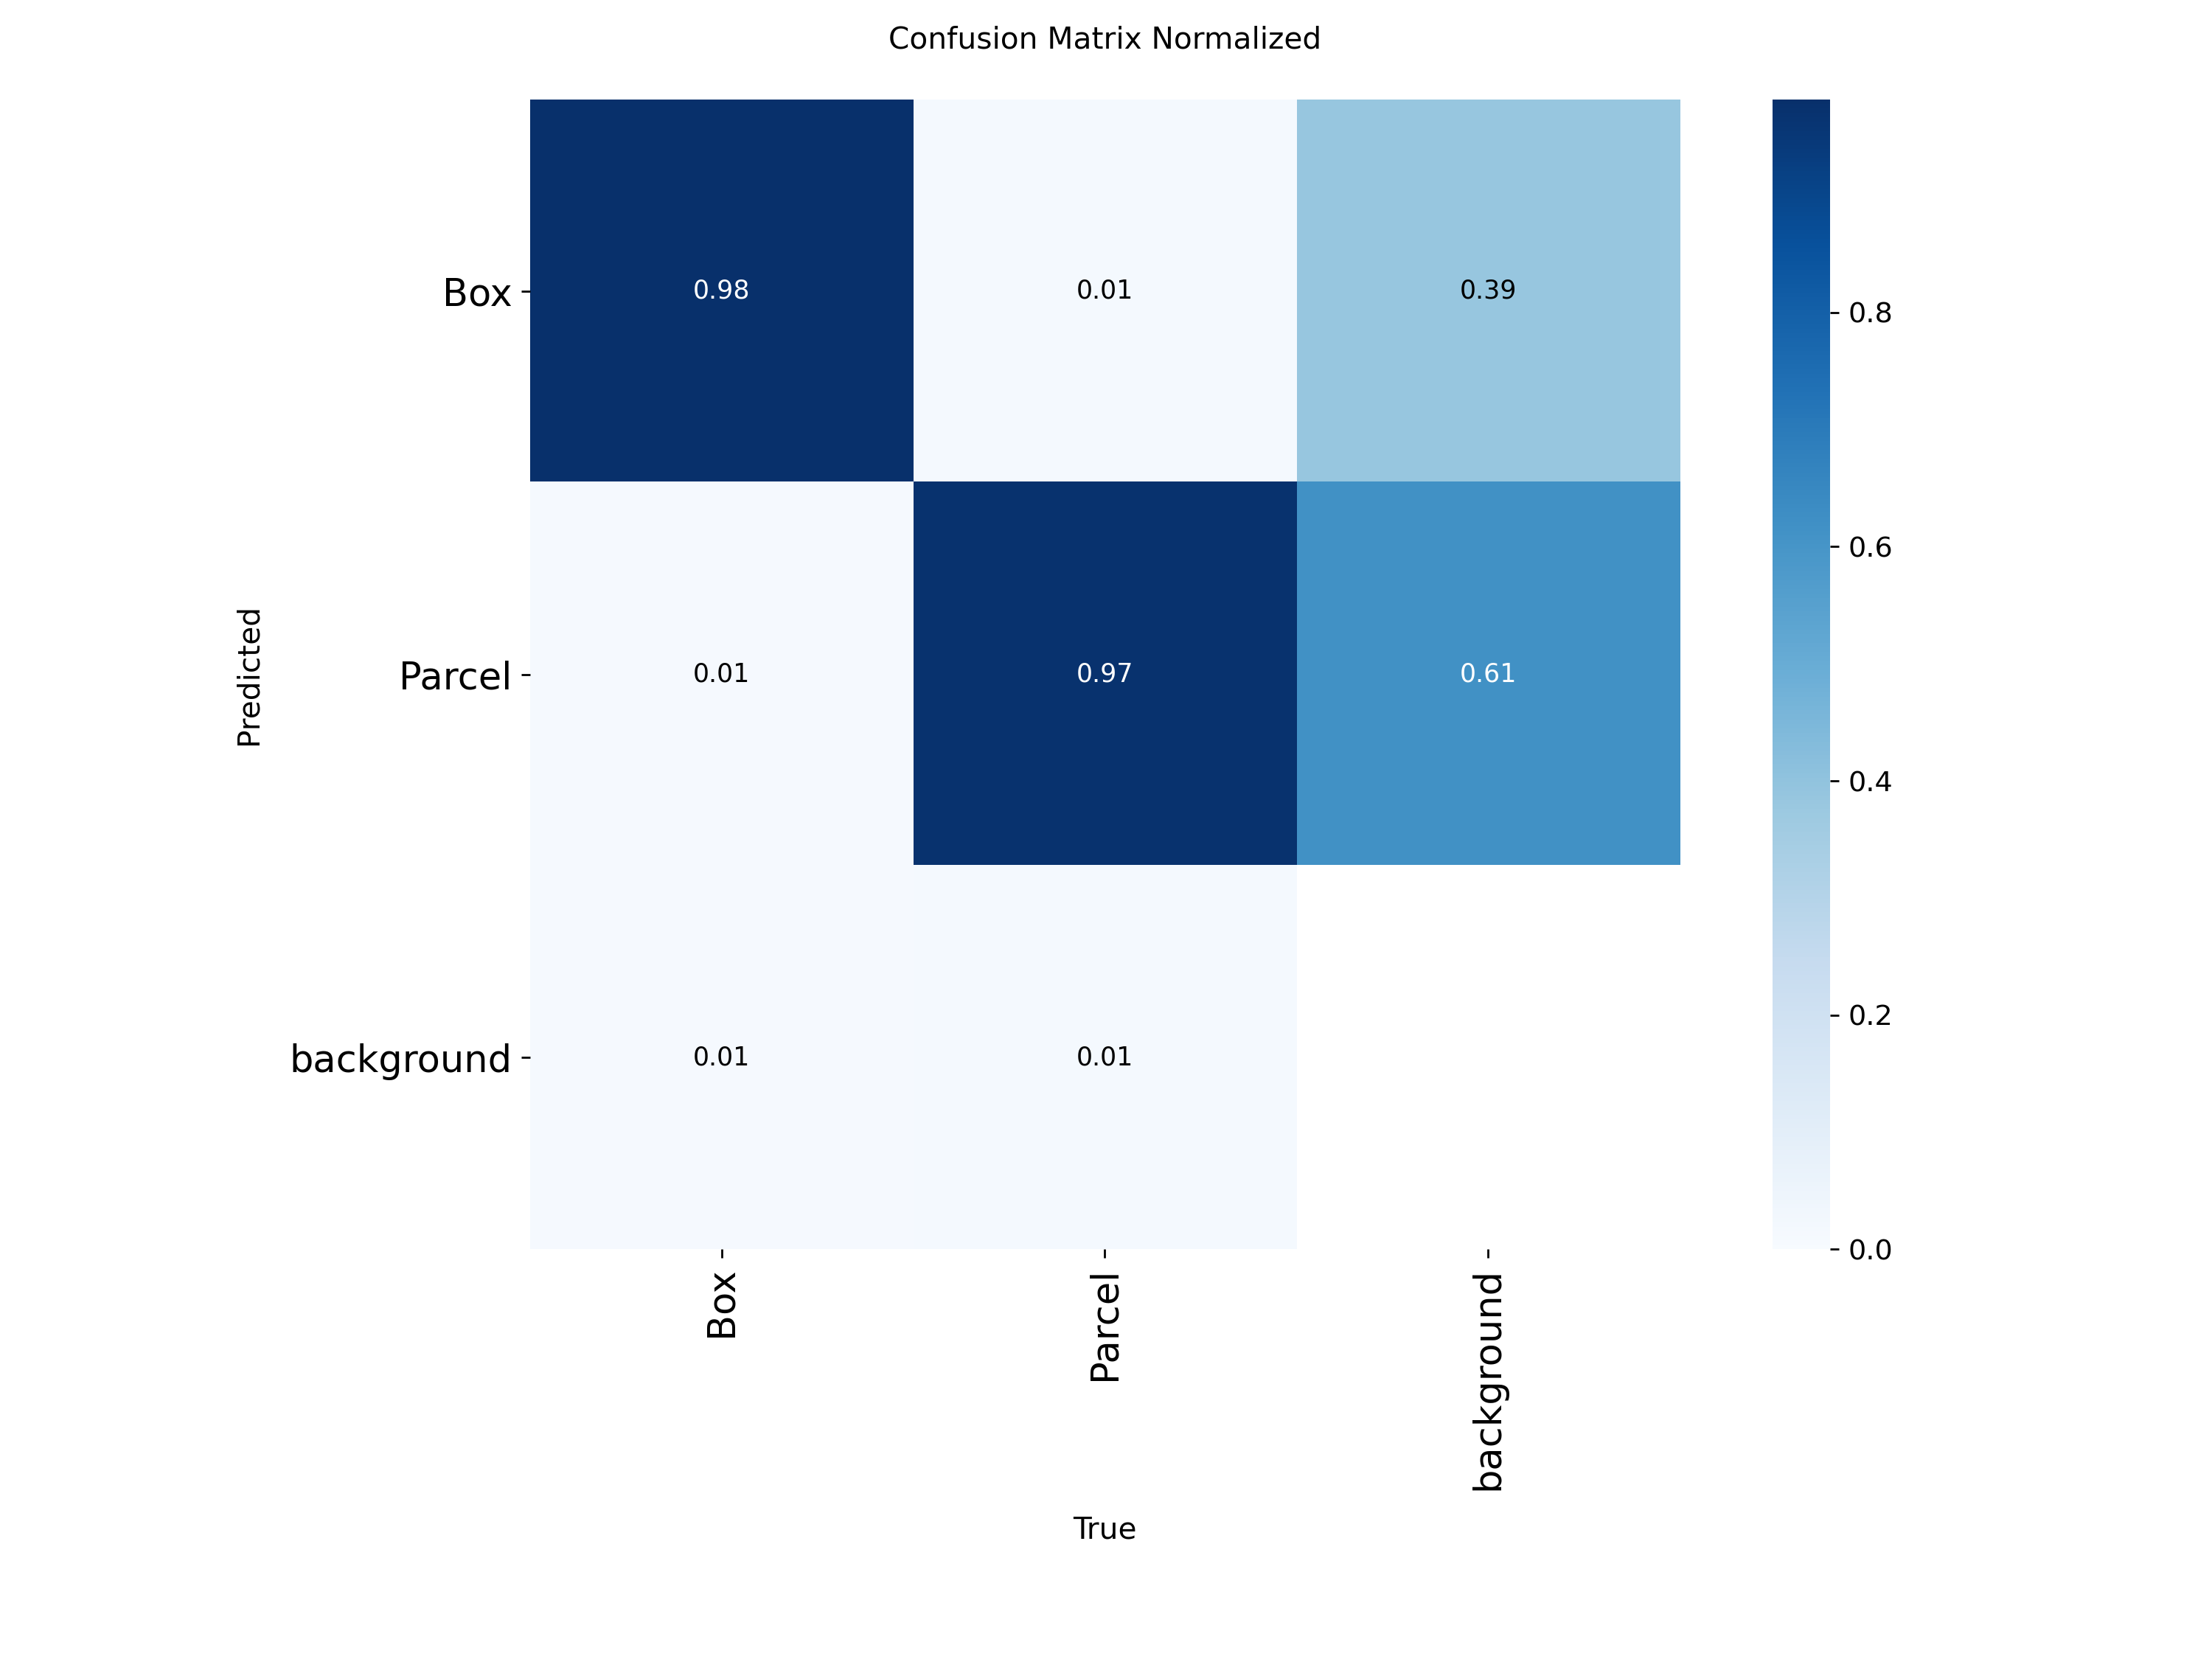

In [ ]:
from IPython.display import Image, display

d = '/content/drive/MyDrive/logistics_project/runs'
display(Image(f'{d}/parcel_box_v8s/results.png'))
display(Image(f'{d}/test_eval/confusion_matrix_normalized.png'))

In [ ]:
from google.colab import files
files.download('/content/drive/MyDrive/logistics_project/runs/parcel_box_v8s/weights/best.pt')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

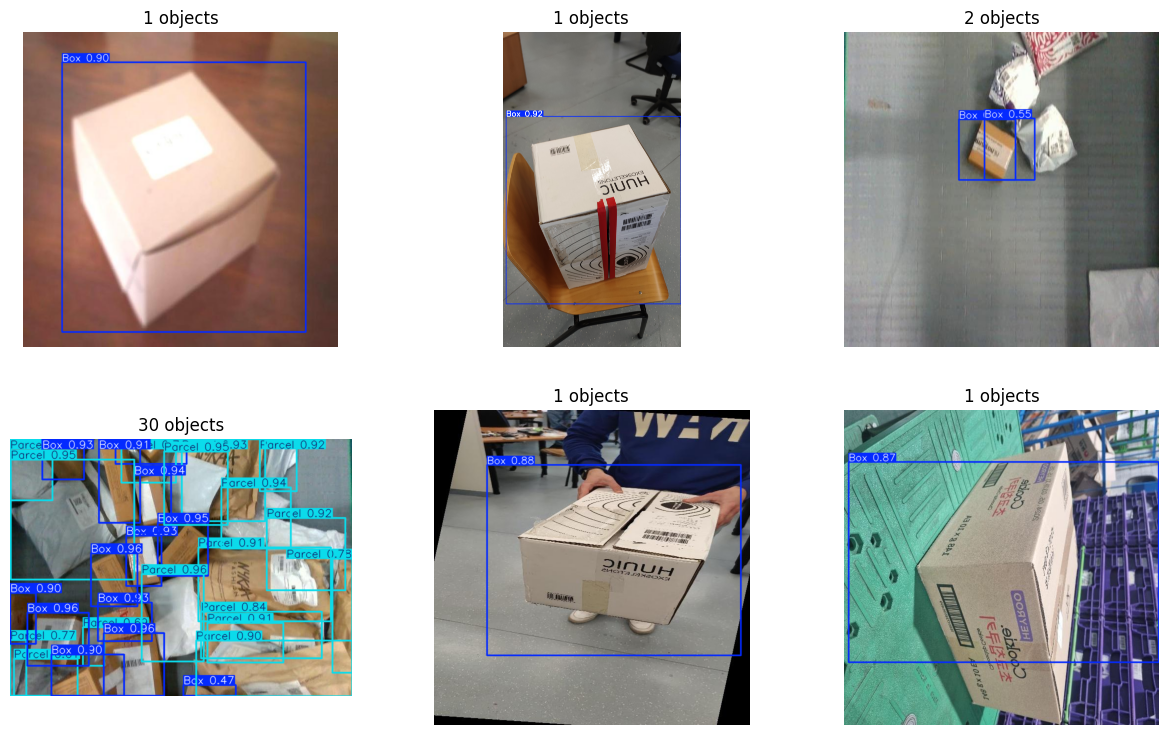

In [ ]:
import glob, random
import matplotlib.pyplot as plt
from ultralytics import YOLO

model = YOLO('/content/drive/MyDrive/logistics_project/runs/parcel_box_v8s/weights/best.pt')

files = random.sample(glob.glob('/content/dataset/test/images/*.jpg'), 6)
plt.figure(figsize=(15, 9))
for i, f in enumerate(files):
    r = model.predict(f, conf=0.25, verbose=False)[0]
    plt.subplot(2, 3, i+1)
    plt.imshow(r.plot()[:, :, ::-1])   # BGR to RGB
    plt.axis('off')
    plt.title(f"{len(r.boxes)} objects")
plt.show()

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


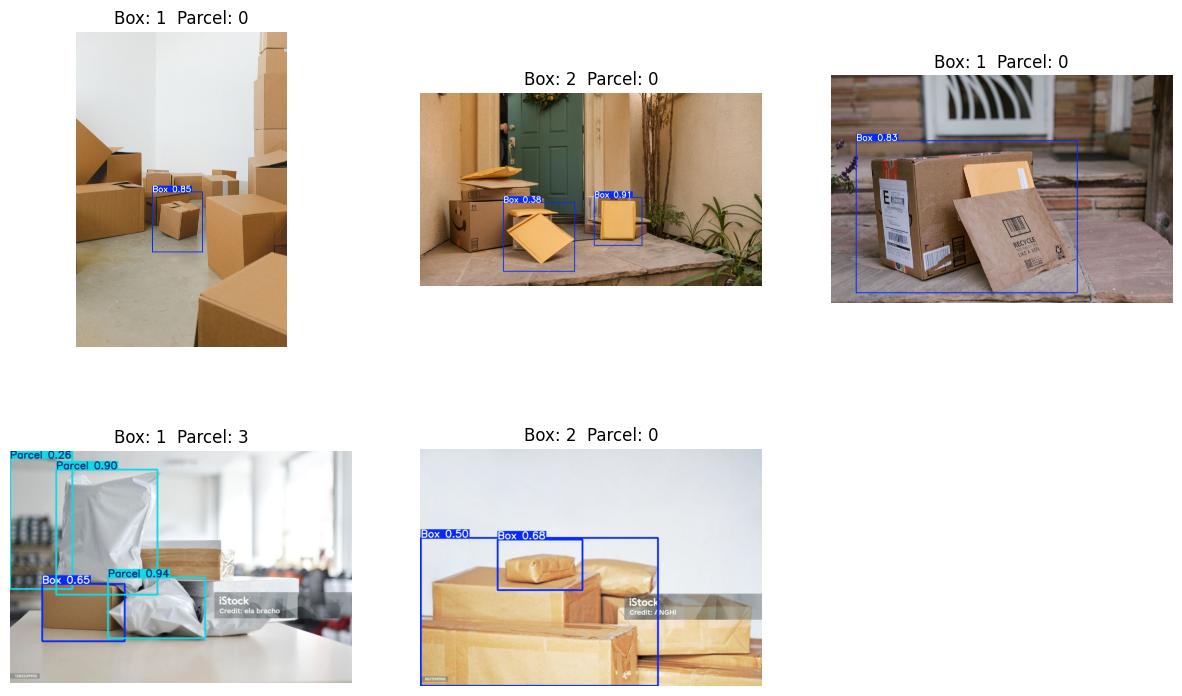

In [3]:
import glob
import matplotlib.pyplot as plt
from ultralytics import YOLO

model = YOLO('/content/drive/MyDrive/logistics_project/runs/parcel_box_v8s/weights/best.pt')

files = glob.glob('/content/drive/MyDrive/logistics_project/my_tests/*')
plt.figure(figsize=(15, 9))
for i, f in enumerate(files[:6]):
    r = model.predict(f, conf=0.25, verbose=False)[0]
    plt.subplot(2, 3, i+1)
    plt.imshow(r.plot()[:, :, ::-1])
    plt.axis('off')
    names = [model.names[int(c)] for c in r.boxes.cls]
    plt.title(f"Box: {names.count('Box')}  Parcel: {names.count('Parcel')}")
plt.show()

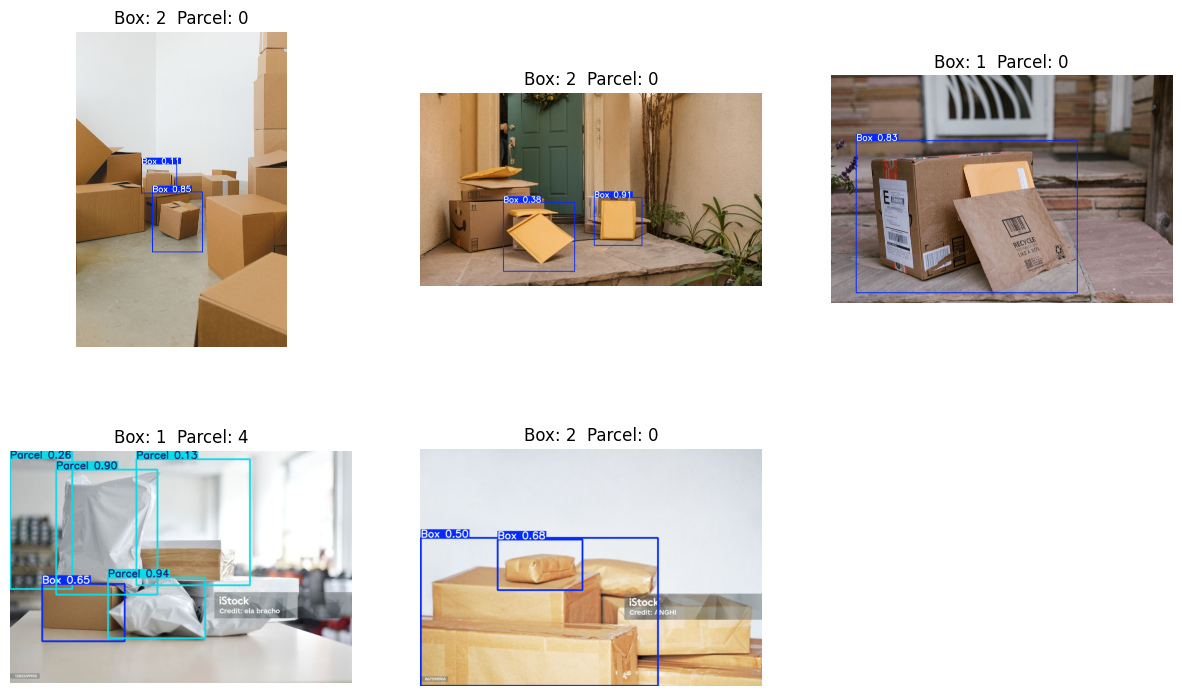

In [4]:
files = glob.glob('/content/drive/MyDrive/logistics_project/my_tests/*')
plt.figure(figsize=(15, 9))
for i, f in enumerate(files[:6]):
    r = model.predict(f, conf=0.10, verbose=False)[0]
    plt.subplot(2, 3, i+1)
    plt.imshow(r.plot()[:, :, ::-1])
    plt.axis('off')
    names = [model.names[int(c)] for c in r.boxes.cls]
    plt.title(f"Box: {names.count('Box')}  Parcel: {names.count('Parcel')}")
plt.show()